## Your pipeline, part 1: inference strategies
HW2, notebook 7 (Kaggle GPU, ~1 h). **No training**: the model is fixed (04's final YOLO11, `final_04.pt`), only the way it predicts changes,
so every difference below comes from the inference strategy alone.

**Needs on Kaggle:** GPU, **Internet ON** (installs Ultralytics), inputs: the competition + the output of notebook 04 (for `final_04.pt`). No API keys.

**Strategies (scored on the official val, every 5th frame, same COCO evaluator as 02-06)**
- `S0_single_pass`: one prediction at the training size, as in notebook 04 (reference).
- `A1_upscaled_pass`: one prediction at 1.33x the training size (small objects become larger).
- `A2_tta_*` (**test-time augmentation**): original + horizontal flip, each at the training size and at 1.33x: 4 passes, merged.
- `A3_tiles_*` (**tiled prediction**, idea of SAHI): the full frame + overlapping crops, each crop resized to the model input, so objects
  are seen ~1.5x larger; boxes are mapped back to the frame and merged.
- `*_nms` vs `*_wbf` (**merging**): class-wise NMS keeps the best box of a cluster and drops the rest; **Weighted Boxes Fusion** averages the
  cluster's coordinates weighted by score and lowers the score of boxes that only few passes found.
- `A2+A3_wbf`: all passes together.

Every pass is computed once per frame and cached, the strategies are different merges of these cached passes.

Sources: SAHI (Akyon et al., 2022, arXiv:2202.06934), Weighted Boxes Fusion (Solovyev et al., 2019, arXiv:1910.13302; implemented here from the paper).

In [1]:
%pip install -q ultralytics

In [2]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
import io, json, time, math, contextlib
from pathlib import Path
from multiprocessing import Pool
import numpy as np, pandas as pd, cv2, torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from torchvision.ops import batched_nms
from ultralytics import YOLO, settings
from ultralytics.utils import DEFAULT_CFG_DICT
settings.update({"wandb": False})
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE -> turn on a GPU in the session options")

INPUT, WORK = Path("/kaggle/input"), Path("/kaggle/working")

def find_all(pattern, depth=5):
    # search attached inputs at increasing nesting depth (Kaggle nests inputs differently per source)
    for d in range(depth):
        hit = sorted(INPUT.glob("/".join(["*"] * d + [pattern])))
        if hit:
            return hit
    return []

def find(pattern):
    hit = find_all(pattern)
    if not hit:
        raise FileNotFoundError(f"{pattern} not found under {INPUT}: check the attached inputs")
    return hit[0]

TEST_CSV = find("test_images.csv"); ROOT = TEST_CSV.parent
VAL_DIR = find("val/annotations_coco.json").parent
METRICS = ["mAP", "AP50", "AP_s", "AP_m", "AP_l", "ms_per_img"]

# ---- settings
MODEL_FILE = "final_04.pt"          # the trained model to use (output of notebook 04)
DEVICE_ID = 0                       # GPU index
VAL_STEP = 5                        # every 5th val frame, as in 02-06
UP_SCALE = 1.33                     # upscaled pass: 1.33x the training size (960 -> 1280)
TILE_ZOOM = 1.5                     # crops are max(W, H) / 1.5 wide, so objects are seen 1.5x larger than in the full pass
TILE_OVERLAP = 0.2                  # minimum overlap between neighbouring crops
NMS_IOU, WBF_IOU = 0.6, 0.55        # merge thresholds (WBF value from the paper)
MAX_DET = 500                       # boxes per image (scoring cap)
MERGE_WORKERS = 4                   # CPU processes for merging boxes

WEIGHTS = find(MODEL_FILE)
ck = torch.load(WEIGHTS, map_location="cpu", weights_only=False)
IMGSZ = int(np.max(ck.get("train_args", {}).get("imgsz", 960)))           # the size the model was trained at
UP_IMGSZ = int(round(IMGSZ * UP_SCALE / 32) * 32)
del ck
model = YOLO(str(WEIGHTS))
PREC = {"quantize": 16} if "quantize" in DEFAULT_CFG_DICT else {"half": True}   # fp16 (the flag was renamed in Ultralytics 8.4)
print(f"model {WEIGHTS} | trained at {IMGSZ} px | upscaled pass {UP_IMGSZ} px")

GPU: Tesla T4
model /kaggle/input/notebooks/vivtrea/04-yolo11/final_04.pt | trained at 960 px | upscaled pass 1280 px


### Evaluation helpers (identical to notebooks 02-05)

In [3]:
def load_gt(path):
    # COCO ground truth; ignored regions (iscrowd=1) are copied to all 8 classes so they ignore detections of any class
    d = json.load(open(path))
    crowd = [a for a in d["annotations"] if a.get("iscrowd")]
    d["annotations"] = [a for a in d["annotations"] if not a.get("iscrowd")]
    nid = max([a["id"] for a in d["annotations"]], default=0) + 1
    for a in crowd:
        for c in range(1, 9):
            d["annotations"].append({**a, "id": nid, "category_id": c, "iscrowd": 1, "area": a["bbox"][2] * a["bbox"][3]})
            nid += 1
    gt = COCO()
    gt.dataset = d
    with contextlib.redirect_stdout(io.StringIO()):
        gt.createIndex()
    return gt

def coco_eval(gt, dets, img_ids):
    # standard COCO bbox metrics, up to 500 detections per image (as in the leaderboard)
    if not dets:
        return dict(mAP=0.0, AP50=0.0, AP_s=0.0, AP_m=0.0, AP_l=0.0)
    with contextlib.redirect_stdout(io.StringIO()):
        E = COCOeval(gt, gt.loadRes(dets), "bbox")
        E.params.imgIds = list(img_ids)
        E.params.maxDets = [1, 10, 500]
        E.evaluate(); E.accumulate(); E.summarize()
    s = E.stats                                  # s[1], s[3:6] already use maxDets[-1] = 500
    prec = E.eval["precision"][:, :, :, 0, -1]   # [IoU, recall, class] for all sizes at 500 dets (pycocotools' s[0] hardcodes 100)
    prec = prec[prec > -1]
    return dict(mAP=float(prec.mean()) if prec.size else -1.0, AP50=s[1], AP_s=s[3], AP_m=s[4], AP_l=s[5])

def write_submission(dets, path):
    # one row per test image: "class score x y w h ..." (0-based class, pixels, top-left corner, max 500 boxes)
    test = pd.read_csv(TEST_CSV)
    by = {}
    for d in dets:
        by.setdefault(d["image_id"], []).append(d)
    rows = []
    for iid in test.image_id:
        top = sorted(by.get(iid, []), key=lambda d: -d["score"])[:500]
        rows.append(" ".join(f"{d['category_id'] - 1} {d['score']:.4f} " + " ".join(f"{v:.1f}" for v in d["bbox"]) for d in top))
    sub = pd.DataFrame({"image_id": test.image_id, "PredictionString": rows})
    sub.to_csv(path, index=False)
    sample = find_all("sample_submission.csv")      # not shipped with this competition's data: ids come from test_images.csv
    if sample:
        assert list(sub.image_id) == list(pd.read_csv(sample[0]).image_id), "image ids differ from sample_submission.csv"
    print(f"saved {path}: {len(sub)} rows, {sum(map(bool, rows))} with detections, {sum(len(r.split()) // 6 for r in rows)} boxes")

In [4]:
# official val: raw frames at original resolution, every VAL_STEP-th frame of each clip; test frames
VAL_GT = load_gt(VAL_DIR / "annotations_coco.json")
_idx = {(p.parent.name, p.name): p for p in (VAL_DIR / "images").rglob("*.jpg")}
_v = pd.DataFrame(VAL_GT.dataset["images"])
_v = _v[(_v.groupby("video").frame_id.rank(method="first").astype(int) - 1) % VAL_STEP == 0]
VAL_ITEMS = [(int(r.id), _idx[(r.video, Path(r.file_name).name)]) for r in _v.itertuples()]
VAL_IDS = [i for i, _ in VAL_ITEMS]
TEST_ITEMS = [(r.image_id, ROOT / r.file_name) for r in pd.read_csv(TEST_CSV).itertuples()]
print(f"{len(VAL_ITEMS)} val frames | {len(TEST_ITEMS)} test frames")

571 val frames | 3811 test frames


### Prediction passes ("views")
Each view returns boxes `[x1, y1, x2, y2, score, class]` in the pixel coordinates of the original frame.
Calls are small (one frame, or the crops of one frame): Ultralytics 8.4 puts a whole list of images into one batch.

In [5]:
def run(images, imgsz):
    # one model call on a few images; returns one (N, 6) array per image
    res = model.predict(images, imgsz=imgsz, conf=0.001, iou=0.6, max_det=MAX_DET, verbose=False, device=DEVICE_ID, **PREC)
    return [np.c_[r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy(), r.boxes.cls.cpu().numpy()].astype(np.float32) for r in res]

def unflip(b, width):
    # boxes predicted on a horizontally flipped image -> original orientation
    b = b.copy(); b[:, [0, 2]] = width - b[:, [2, 0]]
    return b

def nms(b, iou):
    # class-wise NMS, best first, at most MAX_DET boxes
    if not len(b):
        return b
    t = torch.from_numpy(b)
    keep = batched_nms(t[:, :4], t[:, 4], t[:, 5].long(), iou).numpy()
    return b[keep[:MAX_DET]]

def tile_grid(W, H):
    # overlapping crops of side max(W, H) / TILE_ZOOM (clipped to the frame), at least TILE_OVERLAP overlap
    T = int(max(W, H) / TILE_ZOOM)
    tw, th = min(T, W), min(T, H)
    def starts(size, t):
        n = max(1, math.ceil((size - t) / (t * (1 - TILE_OVERLAP))) + 1) if size > t else 1
        return np.linspace(0, size - t, n).round().astype(int)
    return [(x, y, x + tw, y + th) for y in starts(H, th) for x in starts(W, tw)]

def predict_views(img, views):
    # img: BGR frame; returns {view name: (N, 6) array} and the time of each view in ms
    H, W = img.shape[:2]
    out, ms = {}, {}
    flip = np.ascontiguousarray(img[:, ::-1])
    for name in views:
        t0 = time.perf_counter()
        if name == "full":
            out[name] = run([img], IMGSZ)[0]
        elif name == "full_flip":
            out[name] = unflip(run([flip], IMGSZ)[0], W)
        elif name == "up":
            out[name] = run([img], UP_IMGSZ)[0]
        elif name == "up_flip":
            out[name] = unflip(run([flip], UP_IMGSZ)[0], W)
        elif name in ("tiles", "tiles_flip"):
            grid = tile_grid(W, H)
            crops = [img[y0:y1, x0:x1] for x0, y0, x1, y1 in grid]
            if name == "tiles_flip":
                crops = [np.ascontiguousarray(c[:, ::-1]) for c in crops]
            parts = []
            for (x0, y0, x1, y1), b in zip(grid, run(crops, IMGSZ)):
                if name == "tiles_flip":
                    b = unflip(b, x1 - x0)
                # drop boxes cut by an inner crop edge: the neighbouring crop (>= 20 % overlap) or the full pass has the whole object
                e = 2
                cut = (((b[:, 0] <= e) & (x0 > 0)) | ((b[:, 2] >= x1 - x0 - e) & (x1 < W)) |
                       ((b[:, 1] <= e) & (y0 > 0)) | ((b[:, 3] >= y1 - y0 - e) & (y1 < H)))
                b = b[~cut].copy(); b[:, [0, 2]] += x0; b[:, [1, 3]] += y0
                parts.append(b)
            out[name] = nms(np.concatenate(parts), NMS_IOU)        # remove duplicates from overlapping crops
        ms[name] = 1000 * (time.perf_counter() - t0)
    return out, ms

# quick look at the crops of one val frame
img = cv2.imread(str(VAL_ITEMS[0][1])); H, W = img.shape[:2]
print(f"frame {W}x{H} -> {len(tile_grid(W, H))} crops:", tile_grid(W, H))

frame 1344x756 -> 2 crops: [(np.int64(0), np.int64(0), np.int64(896), np.int64(756)), (np.int64(448), np.int64(0), np.int64(1344), np.int64(756))]


### Merging: NMS vs Weighted Boxes Fusion
WBF (Solovyev et al.): boxes of one class are visited from the highest score down; a box joins the first fused box it overlaps with IoU > 0.55,
otherwise it starts a new one. A fused box is the score-weighted average of its members; its score is the mean member score,
multiplied by `min(members, passes) / passes`, so boxes confirmed by many passes rank higher.

In [6]:
def wbf(views, iou_thr=WBF_IOU):
    # views: list of (N, 6) arrays, one per pass; returns fused (M, 6), best first, at most MAX_DET
    n_views = len(views)
    allb = np.concatenate([v for v in views if len(v)] or [np.zeros((0, 6), np.float32)])
    out = []
    for c in np.unique(allb[:, 5]):
        b = allb[allb[:, 5] == c]
        b = b[np.argsort(-b[:, 4])]
        acc = np.zeros((len(b), 4)); fb = np.zeros((len(b), 4)); w = np.zeros(len(b)); cnt = np.zeros(len(b)); m = 0
        for x1, y1, x2, y2, s, _ in b:
            if m:
                f = fb[:m]
                ix = np.clip(np.minimum(f[:, 2], x2) - np.maximum(f[:, 0], x1), 0, None)
                iy = np.clip(np.minimum(f[:, 3], y2) - np.maximum(f[:, 1], y1), 0, None)
                inter = ix * iy
                iou = inter / ((f[:, 2] - f[:, 0]) * (f[:, 3] - f[:, 1]) + (x2 - x1) * (y2 - y1) - inter + 1e-9)
                j = int(np.argmax(iou))
                if iou[j] > iou_thr:
                    acc[j] += s * np.array([x1, y1, x2, y2]); w[j] += s; cnt[j] += 1
                    fb[j] = acc[j] / w[j]
                    continue
            acc[m] = s * np.array([x1, y1, x2, y2]); w[m] = s; cnt[m] = 1; fb[m] = (x1, y1, x2, y2); m += 1
        score = w[:m] / cnt[:m] * np.minimum(cnt[:m], n_views) / n_views
        out.append(np.c_[fb[:m], score, np.full(m, c)])
    if not out:
        return np.zeros((0, 6), np.float32)
    res = np.concatenate(out).astype(np.float32)
    return res[np.argsort(-res[:, 4])][:MAX_DET]

def merge(views, how):
    if how is None:                                         # single pass: as predicted
        return views[0][:MAX_DET]
    if how == "nms":
        return nms(np.concatenate(views), NMS_IOU)
    return wbf(views)

STRATEGIES = {                                              # name: (views, merge)
    "S0_single_pass":   (["full"], None),
    "A1_upscaled_pass": (["up"], None),
    "A2_tta_nms":       (["full", "full_flip", "up", "up_flip"], "nms"),
    "A2_tta_wbf":       (["full", "full_flip", "up", "up_flip"], "wbf"),
    "A3_tiles_nms":     (["full", "tiles"], "nms"),
    "A3_tiles_wbf":     (["full", "tiles"], "wbf"),
    "A2+A3_wbf":        (["full", "full_flip", "up", "up_flip", "tiles", "tiles_flip"], "wbf"),
}
ALL_VIEWS = ["full", "full_flip", "up", "up_flip", "tiles", "tiles_flip"]

def merge_task(args):
    # one image, one strategy (runs in a worker process)
    iid, views, how = args
    t0 = time.perf_counter()
    b = merge(views, how)
    return iid, b, 1000 * (time.perf_counter() - t0)

def merge_all(cache, views, how):
    # merge the cached passes of every frame; returns detections (COCO style) and merge ms per frame
    tasks = [(iid, [cache[iid][v] for v in views], how) for iid in cache]
    # worker processes only for WBF (pure NumPy). NMS uses PyTorch, which can hang inside forked processes
    # once its thread pool was used in the main process; NMS takes only seconds here anyway.
    if MERGE_WORKERS and how == "wbf":
        with Pool(MERGE_WORKERS) as p:
            res = p.map(merge_task, tasks, chunksize=8)
    else:
        res = [merge_task(t) for t in tasks]
    dets = [{"image_id": iid, "category_id": int(r[5]) + 1, "bbox": [float(r[0]), float(r[1]), float(r[2] - r[0]), float(r[3] - r[1])],
             "score": float(r[4])} for iid, b, _ in res for r in b]
    return dets, float(np.mean([t for _, _, t in res]))

### Run all passes once on the val frames

In [7]:
cache, view_ms = {}, {v: [] for v in ALL_VIEWS}
for iid, p in tqdm(VAL_ITEMS, desc="val passes"):
    out, ms = predict_views(cv2.imread(str(p)), ALL_VIEWS)
    cache[iid] = out
    for v, t in ms.items():
        view_ms[v].append(t)
view_ms = {v: float(np.mean(t)) for v, t in view_ms.items()}
print("ms per frame and pass:", {v: round(t, 1) for v, t in view_ms.items()})

ms per frame and pass: {'full': 36.4, 'full_flip': 14.1, 'up': 18.4, 'up_flip': 17.2, 'tiles': 33.3, 'tiles_flip': 70.4}


### Score every strategy

S0_single_pass {'mAP': 0.1699, 'AP50': 0.341, 'AP_s': 0.0981, 'AP_m': 0.1661, 'AP_l': 0.3023}
A1_upscaled_pass {'mAP': 0.1762, 'AP50': 0.3542, 'AP_s': 0.1124, 'AP_m': 0.181, 'AP_l': 0.2843}
A2_tta_nms {'mAP': 0.1906, 'AP50': 0.3814, 'AP_s': 0.1272, 'AP_m': 0.1914, 'AP_l': 0.3164}
A2_tta_wbf {'mAP': 0.1951, 'AP50': 0.3883, 'AP_s': 0.1461, 'AP_m': 0.1959, 'AP_l': 0.3166}
A3_tiles_nms {'mAP': 0.1919, 'AP50': 0.3841, 'AP_s': 0.134, 'AP_m': 0.1921, 'AP_l': 0.3161}
A3_tiles_wbf {'mAP': 0.1915, 'AP50': 0.3812, 'AP_s': 0.1341, 'AP_m': 0.1903, 'AP_l': 0.3206}
A2+A3_wbf {'mAP': 0.2045, 'AP50': 0.4058, 'AP_s': 0.1644, 'AP_m': 0.2058, 'AP_l': 0.3279}


,passes,merge,mAP,AP50,AP_s,AP_m,AP_l,ms_per_img
strategy,,,,,,,,
S0_single_pass,full,-,0.1699,0.3410,0.0981,0.1661,0.3023,36.4153
A1_upscaled_pass,up,-,0.1762,0.3542,0.1124,0.1810,0.2843,18.3949
A2_tta_nms,full+full_flip+up+up_flip,nms,0.1906,0.3814,0.1272,0.1914,0.3164,89.1925
A2_tta_wbf,full+full_flip+up+up_flip,wbf,0.1951,0.3883,0.1461,0.1959,0.3166,192.0603
A3_tiles_nms,full+tiles,nms,0.1919,0.3841,0.1340,0.1921,0.3161,71.0261
A3_tiles_wbf,full+tiles,wbf,0.1915,0.3812,0.1341,0.1903,0.3206,123.2820
A2+A3_wbf,full+full_flip+up+up_flip+tiles+tiles_flip,wbf,0.2045,0.4058,0.1644,0.2058,0.3279,357.3816


notebook 04, final model on val: mAP 0.1699


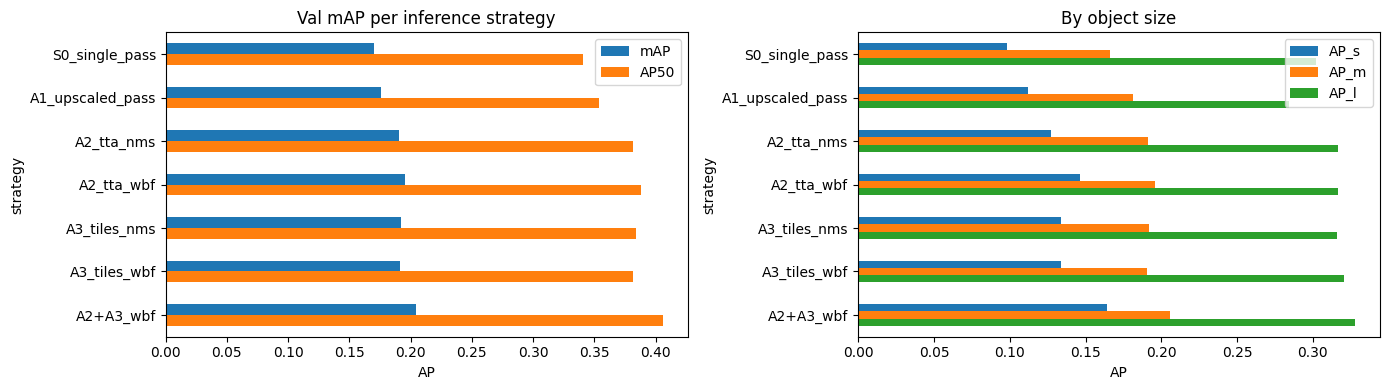

In [8]:
rows = []
for name, (views, how) in STRATEGIES.items():
    dets, merge_ms = merge_all(cache, views, how)
    m = coco_eval(VAL_GT, dets, VAL_IDS)
    rows.append({"strategy": name, "passes": "+".join(views), "merge": how or "-", **m,
                 "ms_per_img": sum(view_ms[v] for v in views) + merge_ms})
    print(name, {k: round(float(v), 4) for k, v in m.items()})
res = pd.DataFrame(rows).set_index("strategy")
res.to_csv(WORK / "results_07_inference.csv")
display(res.round(4))

ref = find_all("results_04_summary.csv")
if ref:                                                     # S0 should match the val check of notebook 04
    r4 = pd.read_csv(ref[0]); print("notebook 04, final model on val: mAP", round(float(r4[r4.split == "val"].mAP.iloc[0]), 4))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
res[["mAP", "AP50"]].plot.barh(ax=ax[0]); ax[0].set(title="Val mAP per inference strategy", xlabel="AP"); ax[0].invert_yaxis()
res[["AP_s", "AP_m", "AP_l"]].plot.barh(ax=ax[1]); ax[1].set(title="By object size", xlabel="AP"); ax[1].invert_yaxis()
plt.tight_layout(); plt.savefig(WORK / "inference_strategies.png", dpi=110); plt.show()

**Observations:**
- Every step helps, mostly for small objects. Upscaling (1.33x): +0.006 mAP, AP_small 0.098 -> 0.112. Flips + upscaling (A2, WBF): +0.025, AP_small 0.146. Tiles (A3): +0.022, AP_small 0.134. All six passes (A2+A3, WBF): **+0.035 (0.170 -> 0.205)**, AP_small 0.098 -> 0.164 (+68 %).
- The cost is ~10x the time per frame (36 -> 357 ms, including the merge), which is fine for an offline submission.
- WBF beats NMS for the flip/scale passes (0.195 vs 0.191; AP_small 0.146 vs 0.127): averaging boxes from several views gives better localisation than keeping one. For full + tiles the two are equal.
- Leaderboard of A2+A3_wbf: 0.2694.

### Test submission with the best strategy
Only the passes the best strategy needs are computed on the 3811 test frames.

In [9]:
best = res.mAP.idxmax()
views, how = STRATEGIES[best]
print("best strategy on val:", best, "| passes:", views, "| merge:", how)
test_cache = {}
for iid, p in tqdm(TEST_ITEMS, desc="test passes"):
    test_cache[iid], _ = predict_views(cv2.imread(str(p)), views)
test_dets, _ = merge_all(test_cache, views, how)
write_submission(test_dets, WORK / f"submission_07_{best.replace('+', '_')}.csv")

best strategy on val: A2+A3_wbf | passes: ['full', 'full_flip', 'up', 'up_flip', 'tiles', 'tiles_flip'] | merge: wbf
saved /kaggle/working/submission_07_A2_A3_wbf.csv: 3811 rows, 3811 with detections, 1741378 boxes
